In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

print("First five rows of dataset:")
print(df.head())


First five rows of dataset:
  Loan_ID     Book_Title        Genre Member_ID Member_Category  Borrower_Age  \
0  L00000  Atomic Habits   Technology     M0197           Adult          35.0   
1  L00001         Ikigai    Biography     M0104           Adult          62.0   
2  L00002     Clean Code  Non-Fiction     M0182         Student          22.0   
3  L00003      Deep Work      Fantasy     M0232           Adult          37.0   
4  L00004      Deep Work    Biography     M0159         Student          28.0   

  Checkout_Date Return_Date  Loan_Duration_Days Overdue  Fine_Amount  \
0    2025-12-13  2025-12-17                   4      No       145.70   
1    2026-09-29  2026-10-03                   4      No        82.95   
2    2025-12-07  2025-12-13                   6      No        40.64   
3    2025-01-09  2025-01-29                  20      No        73.35   
4    2026-08-08  2026-09-02                  25     Yes         5.60   

  Age_Group  Overdue_Days  Late_Fine  Is_Overdue  Mo

In [32]:
import pandas as pd

# Display dataset dimensions

print("Dataset Dimensions:")
if 'df' not in globals():
    df = pd.read_csv("11_library_circulation.csv")
print(df.shape)

# Display column names

print("\nColumn Names:")
print(df.columns.tolist())

# Display data types

print("\nData Types:")
print(df.dtypes)

# Display dataset information

print("\nDataset Information:")
df.info()

# Display statistical summary

print("\nStatistical Summary:")
print(df.describe(include='all'))

Dataset Dimensions:
(659, 18)

Column Names:
['Loan_ID', 'Book_Title', 'Genre', 'Member_ID', 'Member_Category', 'Borrower_Age', 'Checkout_Date', 'Return_Date', 'Loan_Duration_Days', 'Overdue', 'Fine_Amount', 'Age_Group', 'Overdue_Days', 'Late_Fine', 'Is_Overdue', 'Month', 'Month_Name', 'Loan_Duration']

Data Types:
Loan_ID                          str
Book_Title                       str
Genre                            str
Member_ID                        str
Member_Category                  str
Borrower_Age                 float64
Checkout_Date         datetime64[us]
Return_Date           datetime64[us]
Loan_Duration_Days             int64
Overdue                          str
Fine_Amount                  float64
Age_Group                   category
Overdue_Days                 float64
Late_Fine                    float64
Is_Overdue                      bool
Month                          int32
Month_Name                       str
Loan_Duration                float64
dtype: object

Da

In [33]:
# Check missing values

print("Missing Values:")
print(df.isnull().sum())

"""

DataFrame.isnull is an alias for DataFrame.isna.

Detect missing values.

Return a boolean same-sized object indicating if the values are NA. NA values, such as None or numpy.NaN, gets mapped to True values. Everything else gets mapped to False values. Characters such as empty strings '' or numpy.inf are not considered NA values.

Returns

Series/DataFrame Mask of bool values for each element in Series/DataFrame that indicates whether an element is an NA value.

See Also
Series.isnull: Alias of isna.
DataFrame.isnull: Alias of isna.
Series.notna: Boolean inverse of isna.
DataFrame.notna: Boolean inverse of isna.
Series.dropna: Omit axes labels with missing values.
DataFrame.dropna: Omit axes labels with missing values.
isna: Top-level isna.
Examples

Show which entries in a DataFrame are NA.

df = pd.DataFrame(
 dict(
 age=[5, 6, np.nan],
 born=[
 pd.NaT,
 pd.Timestamp("1939-05-27"),
 pd.Timestamp("1940-04-25"),
 ],
 name=["Alfred", "Batman", ""],
 toy=[None, "Batmobile", "Joker"],
 )
)
df
 age born name toy
0 5.0 NaT Alfred NaN
1 6.0 1939-05-27 Batman Batmobile
2 NaN 1940-04-25 Joker
df.isna()
 age born name toy
0 False True False True
1 False False False False
2 True False False False

Show which entries in a Series are NA.

ser = pd.Series([5, 6, np.nan])
ser
0 5.0
1 6.0
2 NaN
dtype: float64
ser.isna()
0 False
1 False
2 True
dtype: bool
Full name: pandas.core.frame.DataFrame.isnull
"""
# Check total missing values
# Check total missing values

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

# Check duplicate Loan_ID records

print("\nDuplicate Loan_ID Records:")
print(df[df.duplicated(subset=['Loan_ID'], keep=False)])

# Count duplicate Loan_ID records

print("\nNumber of Duplicate Loan_ID:")
print(df['Loan_ID'].duplicated().sum())

# Remove duplicate Loan_ID records
# Keep the first occurrence

df = df.drop_duplicates(subset=['Loan_ID'], keep='first')

print("\nDataset after removing duplicates:")
print(df.shape)

Missing Values:
Loan_ID                 0
Book_Title              0
Genre                   0
Member_ID               0
Member_Category         0
Borrower_Age           16
Checkout_Date           0
Return_Date            18
Loan_Duration_Days      0
Overdue                 0
Fine_Amount             0
Age_Group              16
Overdue_Days          659
Late_Fine             659
Is_Overdue              0
Month                   0
Month_Name              0
Loan_Duration          18
dtype: int64

Total Missing Values:
1386

Duplicate Loan_ID Records:
    Loan_ID     Book_Title        Genre Member_ID Member_Category  \
72   L00072      Deep Work    Self-Help     M0117           Adult   
131  L00131     The Hobbit    Biography     M0048         Student   
181  L00181  The Alchemist  Non-Fiction     M0001         Student   
220  L00220  The Alchemist   Technology     M0224         Student   
231  L00231        Sapiens    Self-Help     M0003           Adult   
326  L00326  Python Basics      F

In [34]:
import pandas as pd

# Check missing values before handling

print("Missing values before handling:")
if 'df' not in globals():
    df = pd.read_csv("11_library_circulation.csv")

print(df[['Return_Date', 'Borrower_Age']].isnull().sum())

# Handle missing Borrower_Age using median

median_age = df['Borrower_Age'].median()

df['Borrower_Age'] = df['Borrower_Age'].fillna(median_age)

# Handle missing Return_Date
# Keep missing values as NaT because these may be active loans

df['Return_Date'] = df['Return_Date'].replace(r'^\s*$', np.nan, regex=True)

# Display missing values after handling

print("\nMissing values after handling:")
print(df[['Return_Date', 'Borrower_Age']].isnull().sum())

Missing values before handling:
Return_Date     16
Borrower_Age    16
dtype: int64

Missing values after handling:
Return_Date     16
Borrower_Age     0
dtype: int64


In [35]:
# Convert Checkout_Date into datetime

df['Checkout_Date'] = pd.to_datetime(
    df['Checkout_Date'],
    errors='coerce'
)

# Convert Return_Date into datetime

df['Return_Date'] = pd.to_datetime(
    df['Return_Date'],
    errors='coerce'
)

# Calculate loan duration in days

df['Loan_Duration'] = (
    df['Return_Date'] - df['Checkout_Date']
).dt.days

# Display results

print("Checkout Date and Return Date:")
print(df[['Checkout_Date', 'Return_Date']].head())

print("\nLoan Duration in Days:")
print(df[['Loan_Duration']].head())

Checkout Date and Return Date:
  Checkout_Date Return_Date
0    2025-12-13  2025-12-17
1    2026-09-29  2026-10-03
2    2025-12-07  2025-12-13
3    2025-01-09  2025-01-29
4    2026-08-08  2026-09-02

Loan Duration in Days:
   Loan_Duration
0            4.0
1            4.0
2            6.0
3           20.0
4           25.0


In [36]:


# Total books borrowed

total_books = df['Loan_ID'].nunique()

print("Total Books Borrowed:", total_books)

# Average loan duration
average_duration = pd.to_numeric(
    df['Loan_Duration_Days'],
    errors='coerce'
).mean()

print("Average Loan Duration:",
      round(average_duration, 2), "days")

average_duration = pd.to_numeric(
    df['Loan_Duration_Days'],
    errors='coerce'
).mean()

print("Average Loan Duration:",
      round(average_duration, 2), "days")

# Calculate overdue percentage

# Prefer calculating overdue from Due_Date if available.
# Otherwise, use the existing Overdue column.

if 'Due_Date' in df.columns:

    df['Due_Date'] = pd.to_datetime(
        df['Due_Date'], errors='coerce'
    )

    df['Is_Overdue'] = (
        df['Return_Date'] > df['Due_Date']
    )

elif 'Overdue' in df.columns:

    df['Is_Overdue'] = (
        df['Overdue']
        .astype(str)
        .str.strip()
        .str.lower()
        .isin(['yes', 'true', '1', 'overdue'])
    )

else:
    df['Is_Overdue'] = np.nan
    print("Overdue information is unavailable.")

if df['Is_Overdue'].notna().any():

    overdue_count = df['Is_Overdue'].sum()

    overdue_percentage = (
        overdue_count / df['Is_Overdue'].notna().sum()
    ) * 100

    print("Total Overdue Books:", overdue_count)

    print("Overall Overdue Percentage:",
          round(overdue_percentage, 2), "%")

Total Books Borrowed: 650
Average Loan Duration: 18.41 days
Average Loan Duration: 18.41 days
Total Overdue Books: 148
Overall Overdue Percentage: 22.77 %


Top 10 Most Frequently Borrowed Books:
Book_Title
Deep Work           78
The Alchemist       76
Ikigai              70
Sapiens             65
Data Science 101    65
The Hobbit          62
Clean Code          59
Python Basics       59
Atomic Habits       58
Wings of Fire       58
Name: count, dtype: int64


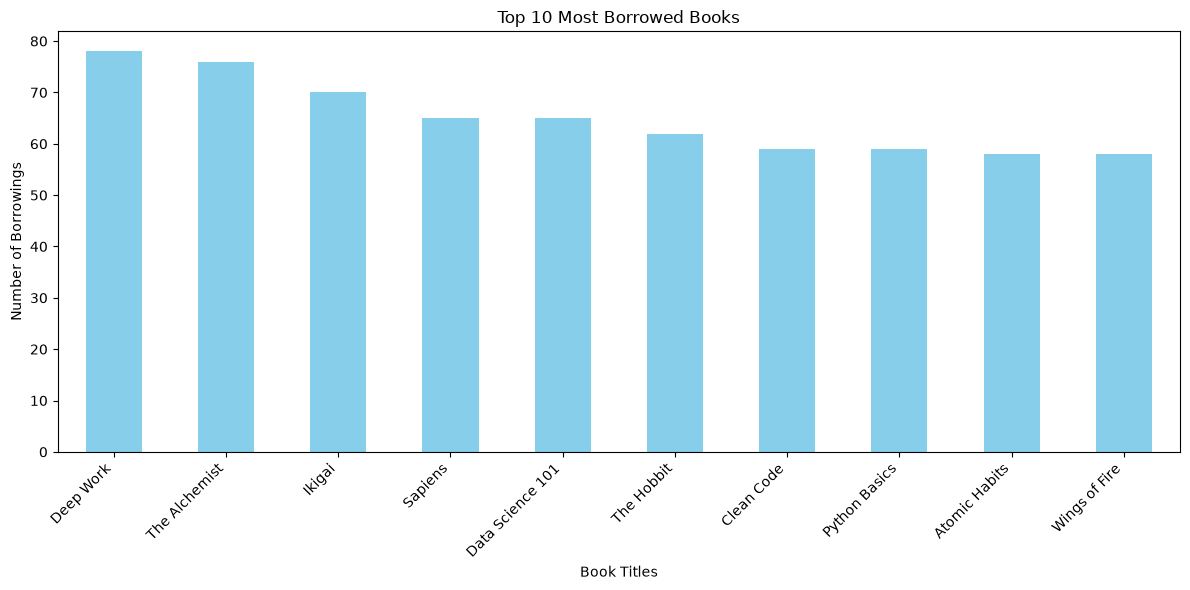

In [37]:
# Count borrowing frequency of each book

top_books = (
    df['Book_Title']
    .value_counts()
    .head(10)
)

print("Top 10 Most Frequently Borrowed Books:")
print(top_books)

# Visualize top 10 books

plt.figure(figsize=(12, 6))

top_books.plot(kind='bar', color='skyblue')

plt.title("Top 10 Most Borrowed Books")

plt.xlabel("Book Titles")

plt.ylabel("Number of Borrowings")

plt.xticks(rotation=45, ha='right')

plt.tight_layout()

plt.show()

Genre Popularity Ranking:
         Genre  Borrow_Count  Rank
0    Biography           123     1
1      Fiction           118     2
2    Self-Help           114     3
3      Fantasy           112     4
4   Technology            98     5
5  Non-Fiction            85     6


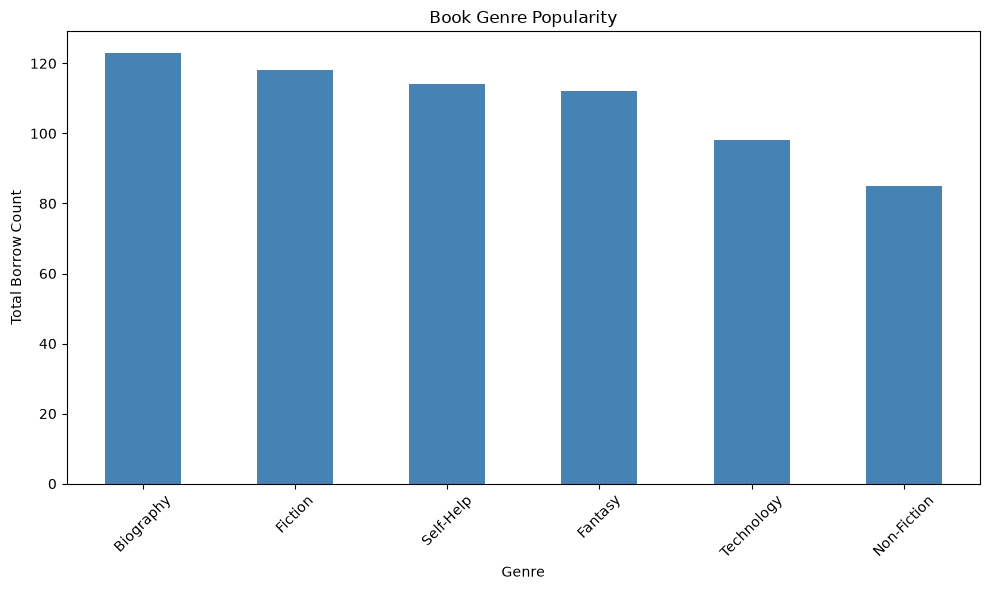

In [38]:
import pandas as pd

# Calculate borrowing count by genre

if 'df' not in globals():
    df = pd.read_csv("11_library_circulation.csv")

genre_count = df['Genre'].value_counts()

# Rank genres

genre_ranking = genre_count.reset_index()

genre_ranking.columns = ['Genre', 'Borrow_Count']

genre_ranking['Rank'] = genre_ranking[
    'Borrow_Count'
].rank(method='dense', ascending=False).astype(int)

# Sort by rank

genre_ranking = genre_ranking.sort_values('Rank')

print("Genre Popularity Ranking:")
print(genre_ranking)

# Visualize genre popularity

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

genre_ranking.plot(
    kind='bar',
    x='Genre',
    y='Borrow_Count',
    color='steelblue',
    legend=False,
    ax=plt.gca()
)

plt.title("Book Genre Popularity")

plt.xlabel("Genre")

plt.ylabel("Total Borrow Count")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

Monthly Borrowing Volume:
January      57
February     45
March        58
April        50
May          65
June         57
July         61
August       61
September    60
October      64
November     30
December     42
Name: Loan_ID, dtype: int64

Peak Reading Month: May
Total Borrowings in Peak Month: 65


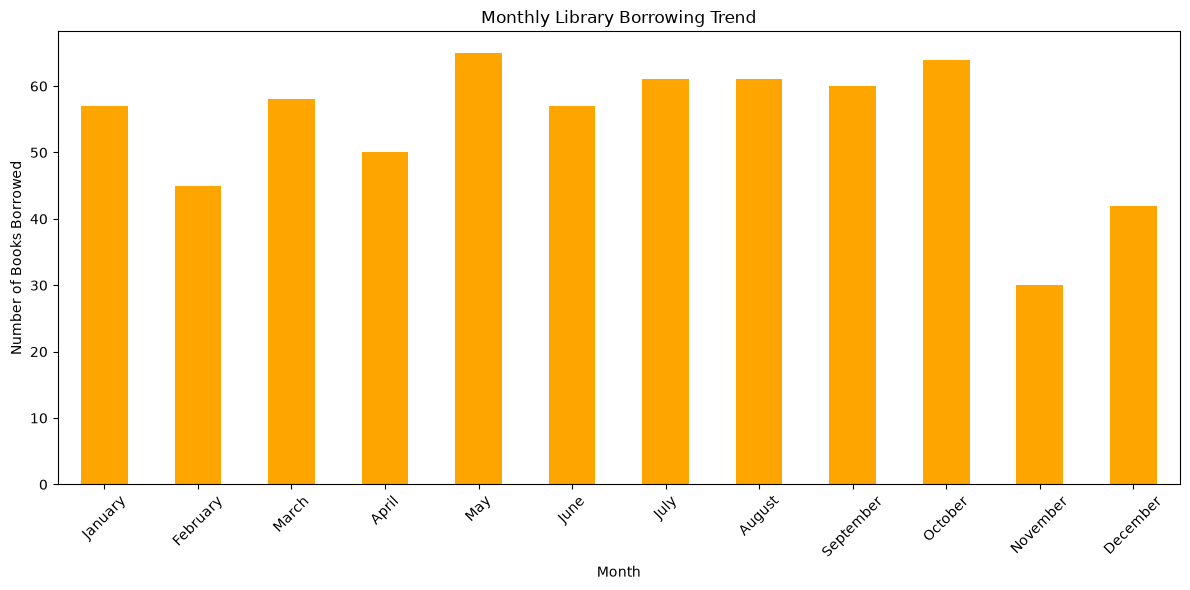

In [39]:
# Extract month from Checkout_Date

df['Checkout_Date'] = pd.to_datetime(
    df['Checkout_Date'],
    errors='coerce'
)

df['Month'] = df['Checkout_Date'].dt.month

df['Month_Name'] = df['Checkout_Date'].dt.month_name()

# Calculate monthly borrowing volume

monthly_borrowing = (
    df.groupby('Month_Name')['Loan_ID']
    .nunique()
)

# Arrange months chronologically

monthly_borrowing = monthly_borrowing.reindex(
    pd.date_range(
        '2024-01-01',
        periods=12,
        freq='MS'
    ).strftime('%B'),
    fill_value=0
)

print("Monthly Borrowing Volume:")
print(monthly_borrowing)

# Identify peak month

peak_month = monthly_borrowing.idxmax()

peak_count = monthly_borrowing.max()

print("\nPeak Reading Month:", peak_month)

print("Total Borrowings in Peak Month:", peak_count)

# Visualization

plt.figure(figsize=(12, 6))

monthly_borrowing.plot(
    kind='bar',
    color='orange'
)

plt.title("Monthly Library Borrowing Trend")

plt.xlabel("Month")

plt.ylabel("Number of Books Borrowed")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

Borrowing Frequency by Member Category:
Member_Category
Adult      248
Senior     105
Student    297
Name: Loan_ID, dtype: int64


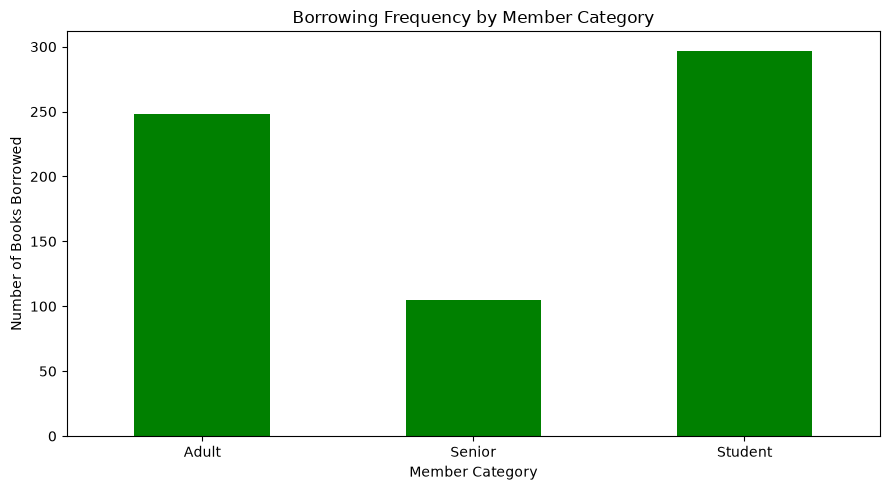

In [40]:
# Calculate borrowing frequency by member category

member_borrowing = (
    df.groupby('Member_Category')['Loan_ID']
    .nunique()
)

print("Borrowing Frequency by Member Category:")
print(member_borrowing)

# Visualize borrowing frequency

plt.figure(figsize=(9, 5))

member_borrowing.plot(
    kind='bar',
    color='green'
)

plt.title("Borrowing Frequency by Member Category")

plt.xlabel("Member Category")

plt.ylabel("Number of Books Borrowed")

plt.xticks(rotation=0)

plt.tight_layout()

plt.show()

Overdue Rate by Book Genre:
Genre
Biography      25.20
Fantasy        28.57
Fiction        19.49
Non-Fiction    16.47
Self-Help      21.05
Technology     24.49
Name: Is_Overdue, dtype: float64

Overdue Rate by Member Category:
Member_Category
Adult      20.56
Senior     20.00
Student    25.59
Name: Is_Overdue, dtype: float64


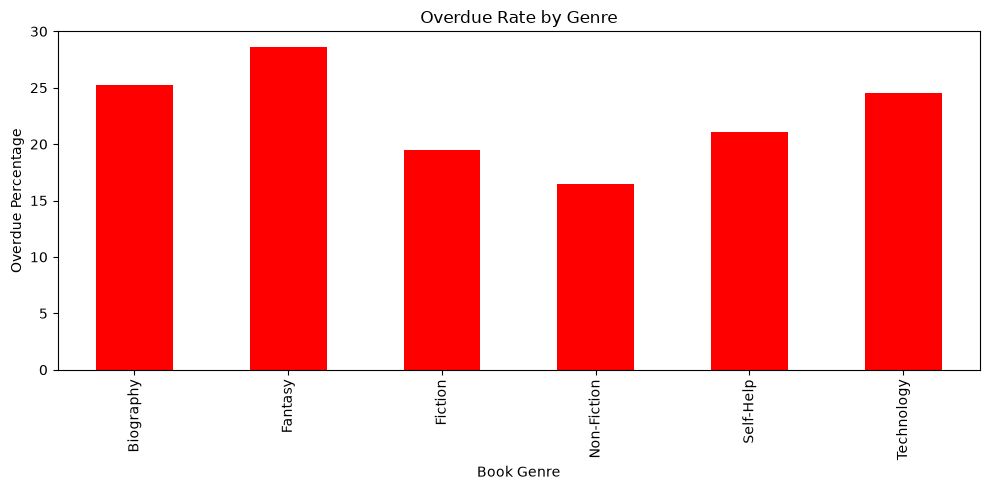

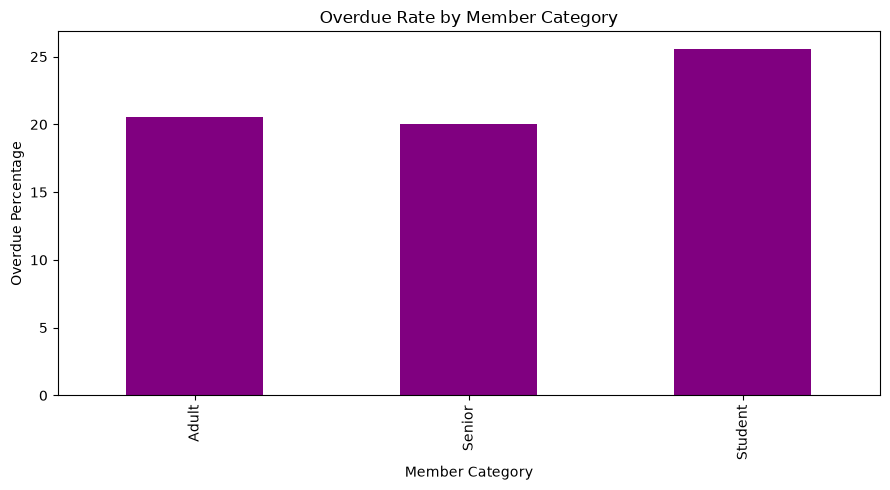

In [41]:
# Calculate overdue rate by genre

# Create Is_Overdue column if not present
if 'Is_Overdue' not in df.columns:
    df['Is_Overdue'] = df['Overdue'].map({'Yes': 1, 'No': 0})

if df['Is_Overdue'].notna().any():

    overdue_genre = (
        df.groupby('Genre')['Is_Overdue']
        .mean() * 100
    )

    print("Overdue Rate by Book Genre:")
    print(overdue_genre.round(2))

    # Calculate overdue rate by member category

    overdue_member = (
        df.groupby('Member_Category')['Is_Overdue']
        .mean() * 100
    )

    print("\nOverdue Rate by Member Category:")
    print(overdue_member.round(2))

    # Visualization

    plt.figure(figsize=(10, 5))

    overdue_genre.plot(
        kind='bar',
        color='red'
    )

    plt.title("Overdue Rate by Genre")

    plt.xlabel("Book Genre")

    plt.ylabel("Overdue Percentage")

    plt.tight_layout()

    plt.show()

    plt.figure(figsize=(9, 5))

    overdue_member.plot(
        kind='bar',
        color='purple'
    )

    plt.title("Overdue Rate by Member Category")

    plt.xlabel("Member Category")

    plt.ylabel("Overdue Percentage")

    plt.tight_layout()

    plt.show()

else:

    print("Cannot calculate overdue rates without overdue information.")

In [42]:
# Assume daily fine rate

daily_fine_rate = 5

# Calculate overdue days

if 'Due_Date' in df.columns:

    df['Overdue_Days'] = (
        df['Return_Date'] - df['Due_Date']
    ).dt.days.clip(lower=0)

elif 'Overdue_Days' in df.columns:

    df['Overdue_Days'] = pd.to_numeric(
        df['Overdue_Days'],
        errors='coerce'
    ).clip(lower=0)

else:

    df['Overdue_Days'] = float('nan')

# Calculate estimated late fine

df['Late_Fine'] = (
    df['Overdue_Days'] * daily_fine_rate
)

# Calculate total estimated fines

total_fines = df['Late_Fine'].sum()

print("Daily Fine Rate: ₹", daily_fine_rate)

print("Total Estimated Late Fines: ₹",
      round(total_fines, 2))

# Display fine details

print("\nLate Fine Details:")

print(
    df[['Loan_ID', 'Overdue_Days', 'Late_Fine']].head(10)
)

Daily Fine Rate: ₹ 5
Total Estimated Late Fines: ₹ 0.0

Late Fine Details:
  Loan_ID  Overdue_Days  Late_Fine
0  L00000           NaN        NaN
1  L00001           NaN        NaN
2  L00002           NaN        NaN
3  L00003           NaN        NaN
4  L00004           NaN        NaN
5  L00005           NaN        NaN
6  L00006           NaN        NaN
7  L00007           NaN        NaN
8  L00008           NaN        NaN
9  L00009           NaN        NaN


Q1: 10.0
Q3: 27.0
IQR: 17.0
Lower Limit: -15.5
Upper Limit: 52.5

Unusually Long Loan Durations:
Empty DataFrame
Columns: [Loan_ID, Book_Title, Loan_Duration_Days]
Index: []


C:\Users\Poorvi Gautam\AppData\Local\Temp\ipykernel_8148\4167744588.py:50: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(duration, vert=False)


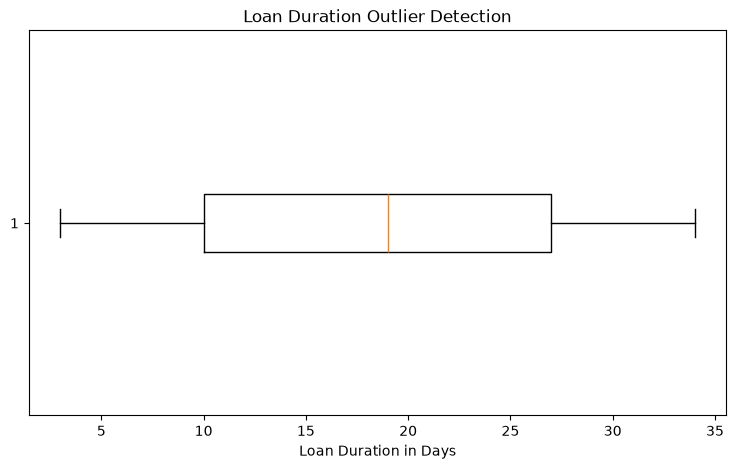

In [43]:
# Remove missing loan durations

duration = pd.to_numeric(df['Loan_Duration_Days'], errors='coerce').dropna()

# Calculate Q1 and Q3

Q1 = np.percentile(duration, 25)

Q3 = np.percentile(duration, 75)

# Calculate IQR

IQR = Q3 - Q1

# Calculate upper and lower limits

lower_limit = Q1 - 1.5 * IQR

upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)

print("Q3:", Q3)

print("IQR:", IQR)

print("Lower Limit:", lower_limit)

print("Upper Limit:", upper_limit)

# Identify outliers

outliers = df[
    (df['Loan_Duration_Days'] < lower_limit) |
    (df['Loan_Duration_Days'] > upper_limit)
]

print("\nUnusually Long Loan Durations:")

print(
    outliers[
        ['Loan_ID', 'Book_Title', 'Loan_Duration_Days']
    ]
)

# Visualize outliers

plt.figure(figsize=(9, 5))

plt.boxplot(duration, vert=False)

plt.title("Loan Duration Outlier Detection")

plt.xlabel("Loan Duration in Days")

plt.show()

In [44]:
# Remove missing loan duration values

loan_duration = pd.to_numeric(
      df['Loan_Duration_Days'],
      errors='coerce'
).dropna()

# Convert to NumPy array

duration_array = np.array(loan_duration)

# Calculate mean

mean_duration = np.mean(duration_array)

# Calculate median

median_duration = np.median(duration_array)

# Calculate standard deviation

std_duration = np.std(duration_array)

# Display results

print("Statistical Analysis of Loan Duration")

print("-------------------------------------")

print("Mean Loan Duration:",
      round(mean_duration, 2), "days")

print("Median Loan Duration:",
      round(median_duration, 2), "days")

print("Standard Deviation:",
      round(std_duration, 2), "days")

Statistical Analysis of Loan Duration
-------------------------------------
Mean Loan Duration: 18.41 days
Median Loan Duration: 19.0 days
Standard Deviation: 9.44 days


Borrower Age Groups:
    Borrower_Age Age_Group
0           35.0    Adults
1           62.0   Seniors
2           22.0    Adults
3           37.0    Adults
4           28.0    Adults
5           24.0    Adults
6           23.0    Adults
7           25.0    Adults
8           50.0    Adults
9           39.0    Adults
10          41.0    Adults
11          44.0    Adults
12          62.0   Seniors
13          70.0   Seniors
14          47.0    Adults
15          55.0    Adults
16          62.0   Seniors
17          58.0    Adults
18          21.0    Adults
19          78.0   Seniors

Number of Borrowers in Each Age Group:
Age_Group
Children       4
Teenagers     66
Adults       394
Seniors      186
Name: count, dtype: int64


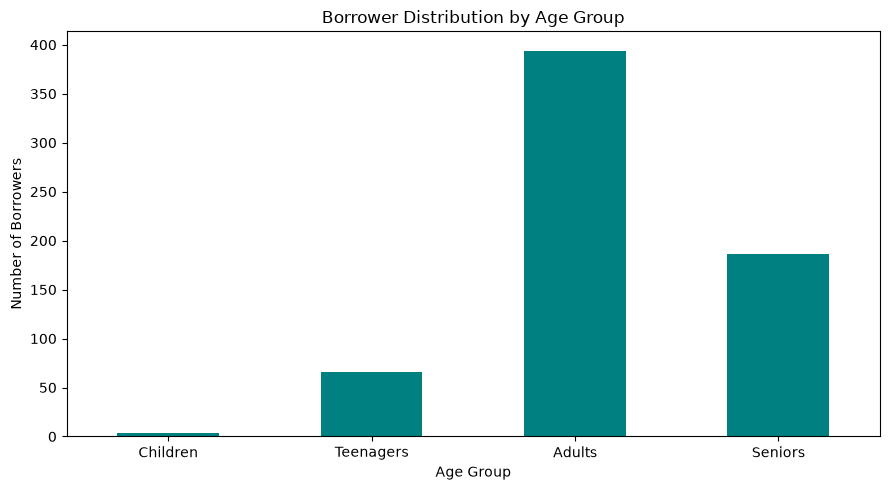

In [45]:
import numpy as np

# Define age ranges

bins = [0, 12, 19, 59, np.inf]

labels = [
    'Children',
    'Teenagers',
    'Adults',
    'Seniors'
]

# Create age group column

df['Age_Group'] = pd.cut(
    df['Borrower_Age'],
    bins=bins,
    labels=labels,
    include_lowest=True
)

# Display borrower age groups

print("Borrower Age Groups:")

print(
    df[
        ['Borrower_Age', 'Age_Group']
    ].head(20)
)

# Count borrowers in each age group

age_group_count = df['Age_Group'].value_counts(
    sort=False
)

print("\nNumber of Borrowers in Each Age Group:")

print(age_group_count)

# Visualize age groups

plt.figure(figsize=(9, 5))

age_group_count.plot(
    kind='bar',
    color='teal'
)

plt.title("Borrower Distribution by Age Group")

plt.xlabel("Age Group")

plt.ylabel("Number of Borrowers")

plt.xticks(rotation=0)

plt.tight_layout()

plt.show()